<a href="https://colab.research.google.com/github/MrdnvShafiga/Machine-Learning-/blob/main/Medical_Charges_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('medical-charges.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
pd.options.display.max_columns = None
display(df)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
df.columns.tolist()

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df = df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

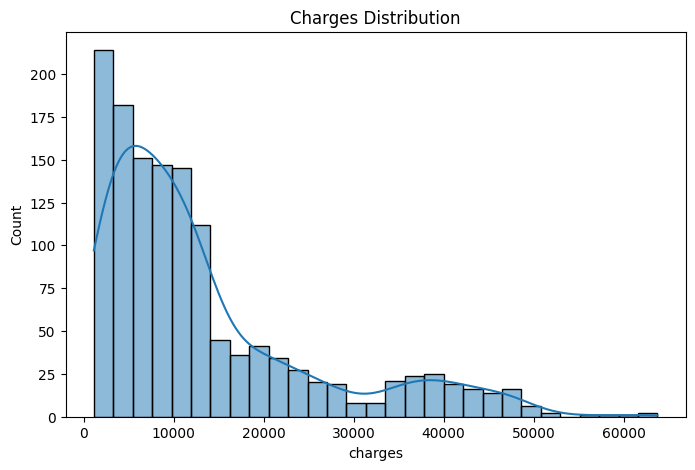

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df['charges'], kde=True)
plt.title("Charges Distribution")
plt.show()

In [11]:
df['charges'].skew()

np.float64(1.5153909108403483)

In [12]:
numeric_cols = df.select_dtypes(exclude='object').columns.tolist()
numeric_cols.remove("charges")

numeric_cols

['age', 'bmi', 'children']

In [13]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()

categorical_cols

['sex', 'smoker', 'region']

In [14]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


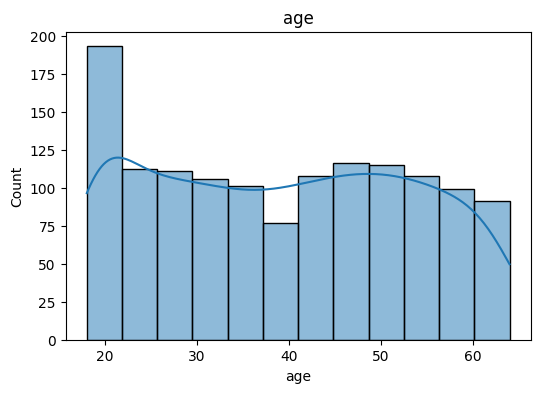

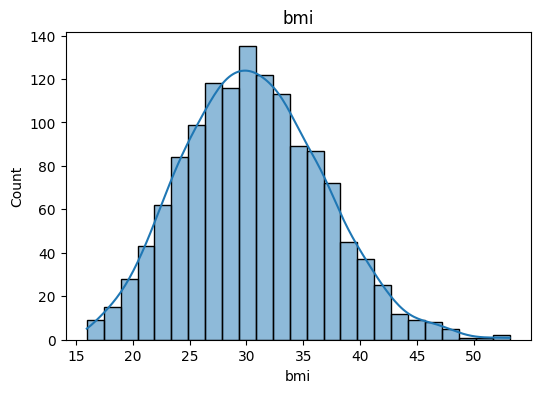

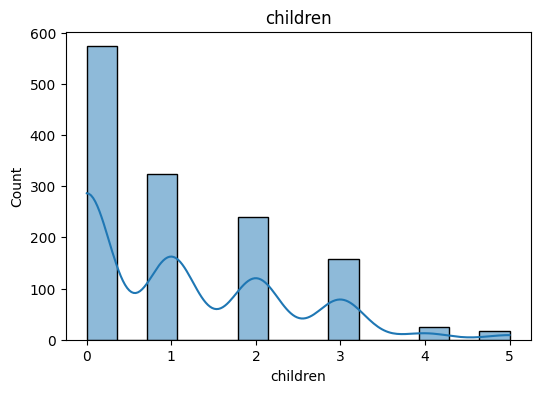

In [15]:
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()

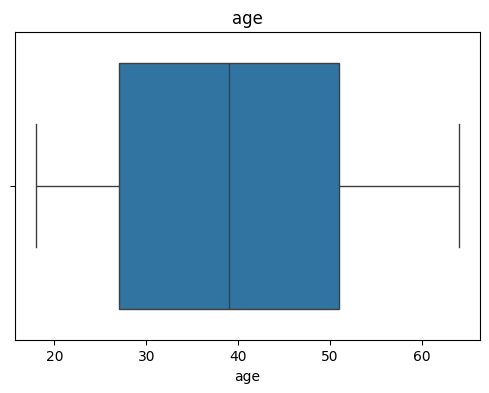

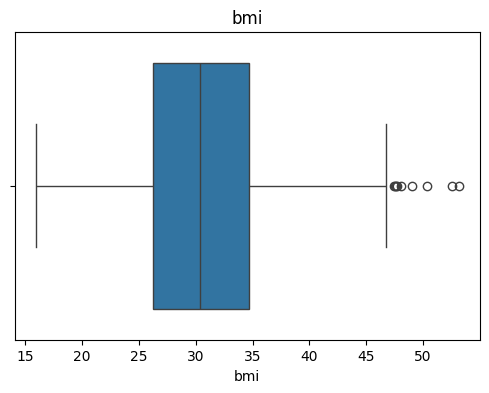

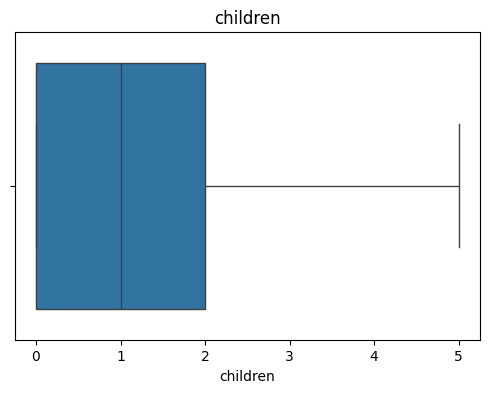

In [16]:
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

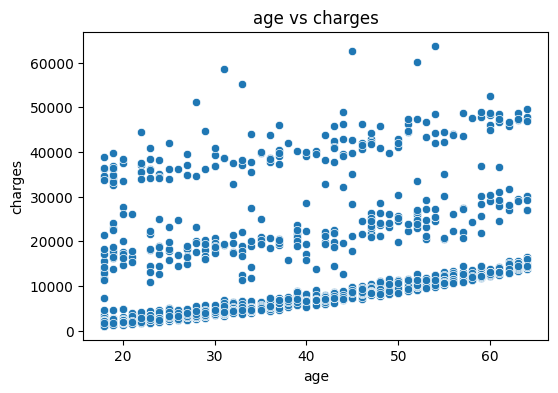

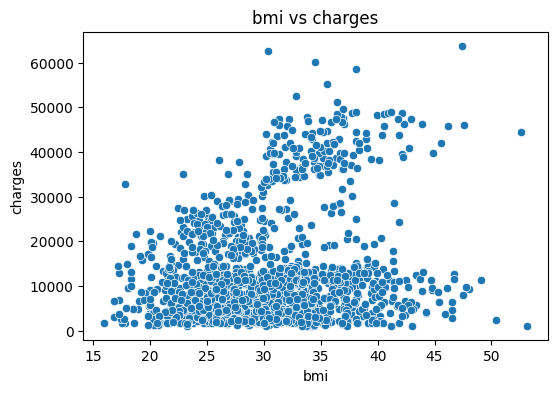

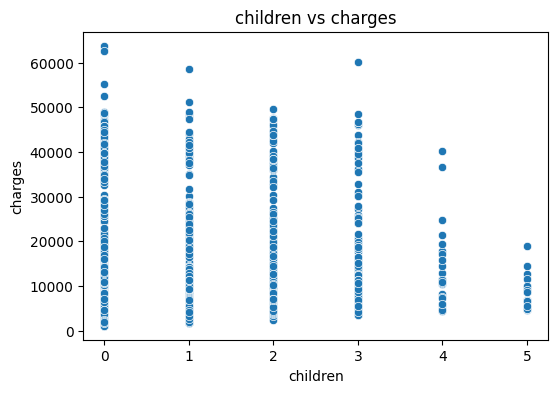

In [17]:
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=df[col], y=df["charges"])
    plt.title(f"{col} vs charges")
    plt.show()

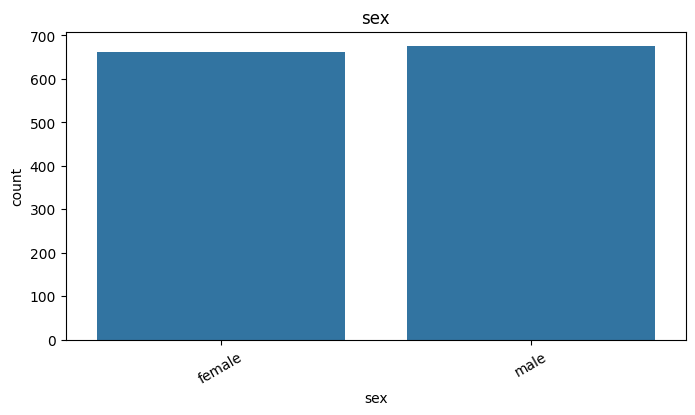

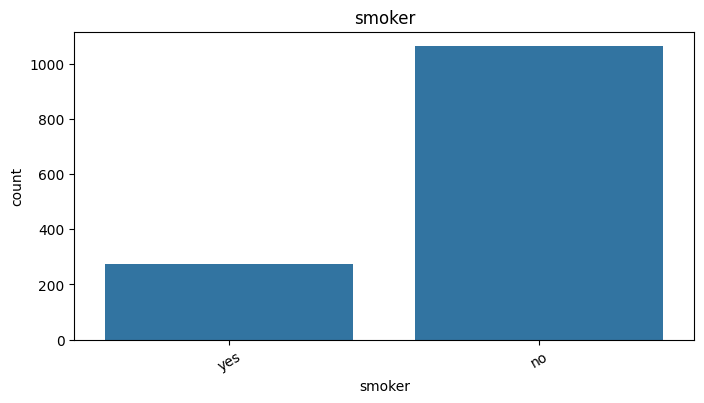

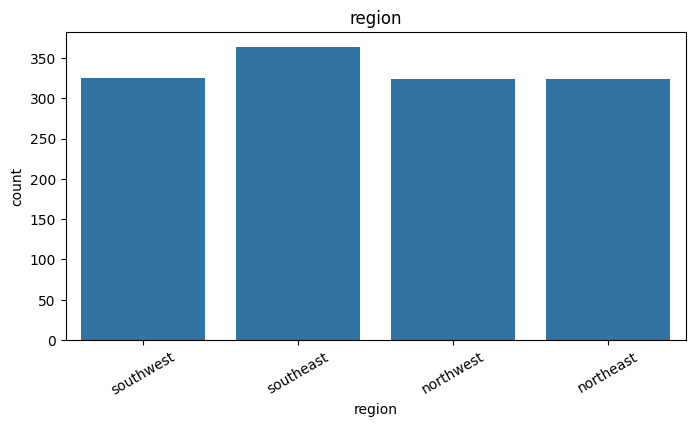

In [18]:
for col in categorical_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=col)
    plt.xticks(rotation=30)
    plt.title(col)
    plt.show()

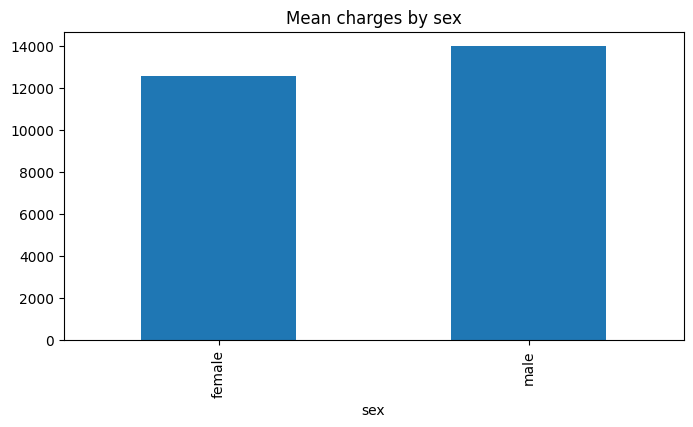

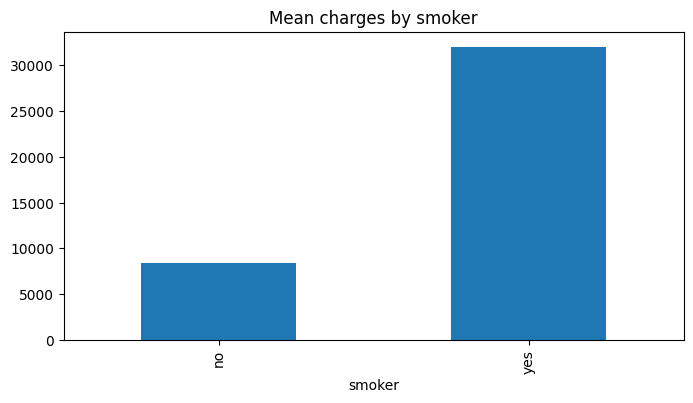

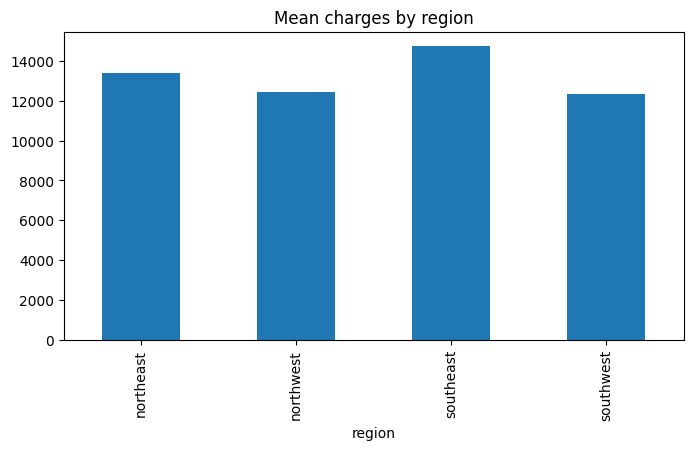

In [19]:
for col in categorical_cols:
    plt.figure(figsize=(8,4))
    df.groupby(col)["charges"].mean().plot(kind="bar")
    plt.title(f"Mean charges by {col}")
    plt.show()

In [20]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


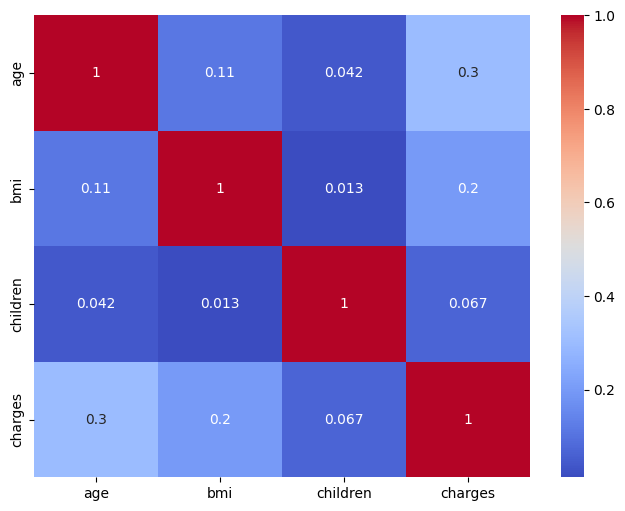

In [21]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [22]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, outliers)

age 0
bmi 9
children 0


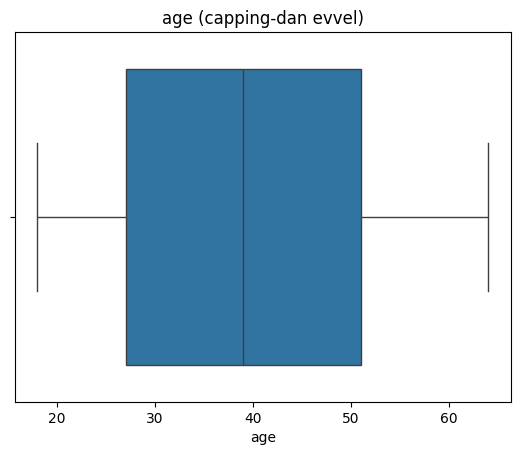

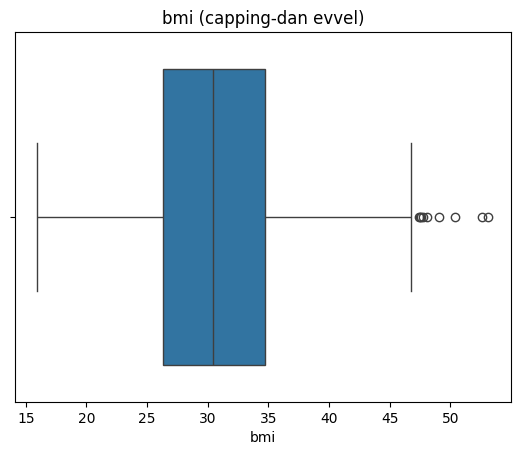

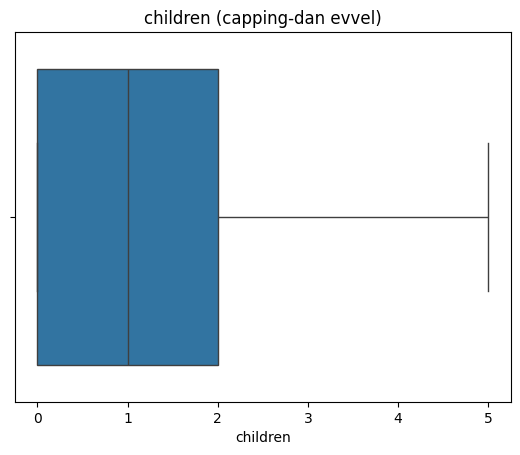

In [23]:
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(f"{col} (capping-dan evvel)")
    plt.show()

In [24]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df[col] = np.where(df[col] > upper, upper, df[col])
    df[col] = np.where(df[col] < lower, lower, df[col])

/tmp/ipykernel_722/2361626512.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = np.where(df[col] > upper, upper, df[col])
/tmp/ipykernel_722/2361626512.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = np.where(df[col] < lower, lower, df[col])
/tmp/ipykernel_722/2361626512.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata

In [25]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [26]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["smoker"] = le.fit_transform(df["smoker"])

/tmp/ipykernel_722/602113603.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["smoker"] = le.fit_transform(df["smoker"])


In [27]:
df_encoded

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,16884.92400,False,True,False,False,True
1,18.0,33.770,1.0,1725.55230,True,False,False,True,False
2,28.0,33.000,3.0,4449.46200,True,False,False,True,False
3,33.0,22.705,0.0,21984.47061,True,False,True,False,False
4,32.0,28.880,0.0,3866.85520,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50.0,30.970,3.0,10600.54830,True,False,True,False,False
1334,18.0,31.920,0.0,2205.98080,False,False,False,False,False
1335,18.0,36.850,0.0,1629.83350,False,False,False,True,False
1336,21.0,25.800,0.0,2007.94500,False,False,False,False,True


In [28]:
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [32]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [33]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

In [34]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=1.0, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

In [35]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=300, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

In [36]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train_scaled, y_train)
y_pred_gb = gb_model.predict(X_test_scaled)

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

def get_metrics(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,

        "MAPE (%)": mape * 100
    }

In [38]:
results = [
    get_metrics(y_test, y_pred_lr, "Linear Regression"),
    get_metrics(y_test, y_pred_ridge, "Ridge Regression"),
    get_metrics(y_test, y_pred_lasso, "Lasso Regression"),
    get_metrics(y_test, y_pred_rf, "Random Forest"),
    get_metrics(y_test, y_pred_gb, "Gradient Boosting"),
]

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False).reset_index(drop=True)
results_df

,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Gradient Boosting,2497.880388,1.806881e+07,4250.741904,0.901670,31.382790
1,Random Forest,2621.659406,2.179376e+07,4668.378206,0.881398,36.969097
2,Linear Regression,4181.898079,3.545290e+07,5954.233965,0.807065,41.648830
3,Lasso Regression,4182.064217,3.546024e+07,5954.850283,0.807025,41.653505
4,Ridge Regression,4184.470504,3.548732e+07,5957.123386,0.806878,41.693090


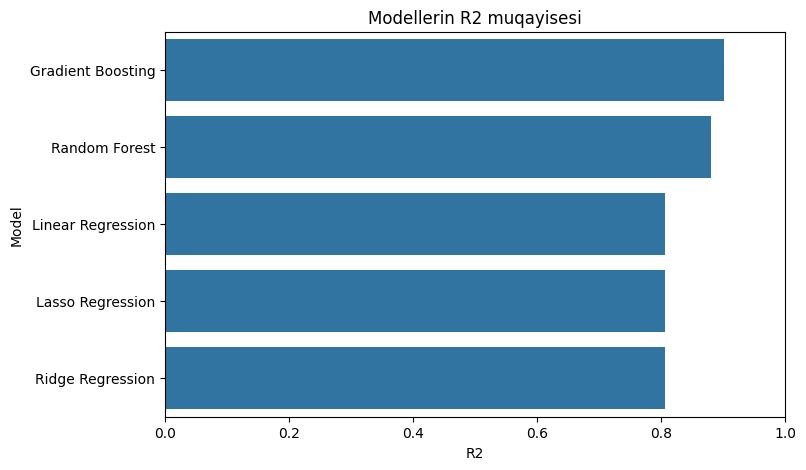

In [39]:
plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x="R2", y="Model")
plt.title("Modellerin R2 muqayisesi")
plt.xlim(0,1)
plt.show()

In [40]:
best_model_name = results_df.iloc[0]["Model"]
best_model_name

'Gradient Boosting'

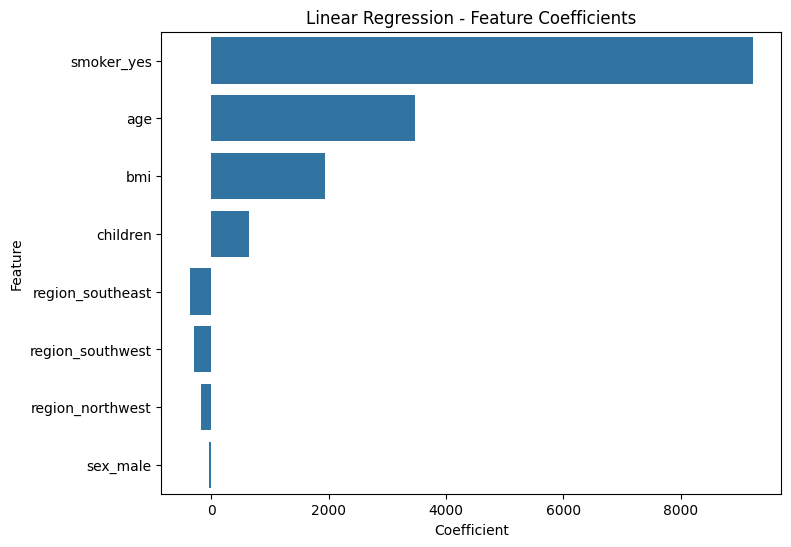

In [41]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_
})

coef_df = coef_df.sort_values(by="Coefficient", key=abs, ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(data=coef_df, x="Coefficient", y="Feature")
plt.title("Linear Regression - Feature Coefficients")
plt.show()

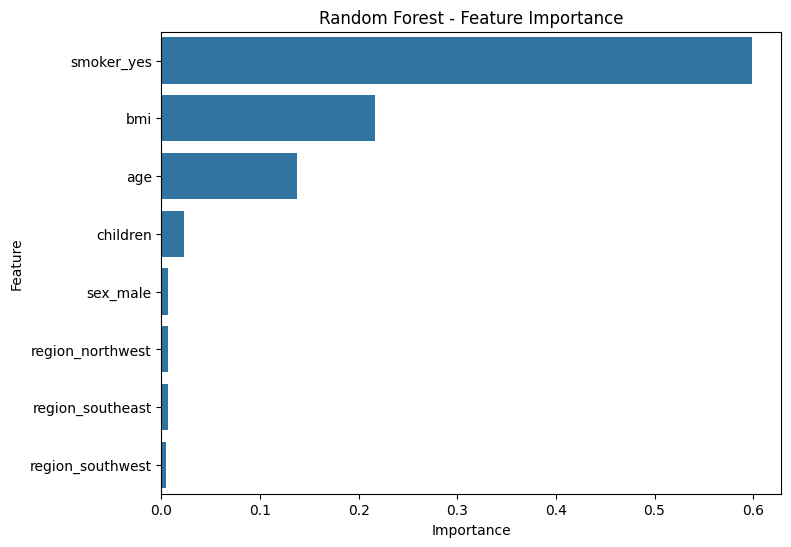

In [42]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest - Feature Importance")
plt.show()

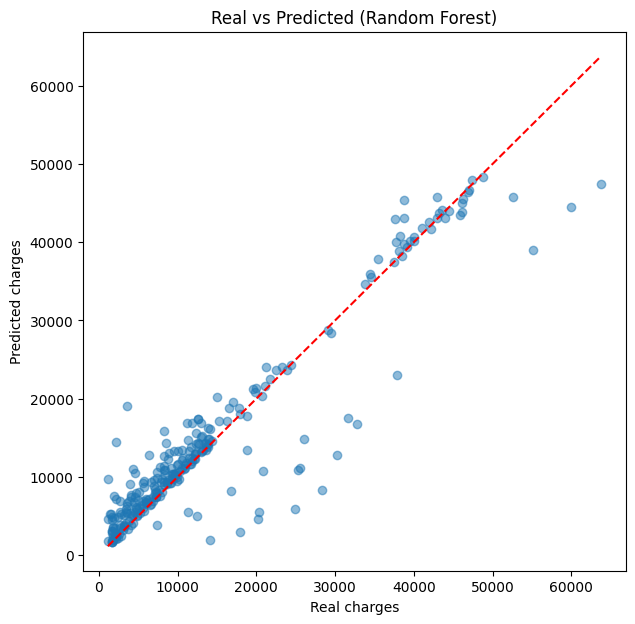

In [43]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Real charges")
plt.ylabel("Predicted charges")
plt.title("Real vs Predicted (Random Forest)")
plt.show()

Bu datasetdə hədəf dəyişən (charges) qeyri-xətti amillərlə, xüsusən smoker statusunun bmi və age ilə qarşılıqlı təsiri ilə güclü şəkildə bağlı olduğu üçün ağac-əsaslı modellər (Random Forest, Gradient Boosting) sadə Linear Regression-dan daha yüksək R2 və daha az xəta göstərir. Lakin Linear, Ridge və Lasso modelləri daha asan izah oluna bildiyindən (biznes üçün "hansı feature nə qədər təsir edir" sualına birbaşa cavab verdiyi üçün) praktikada hansı modelin seçiləcəyi məqsəddən — dəqiqlik yoxsa izaholunma — asılıdır. Yuxarıdakı results_df cədvəli bu qərarın ədədi əsasını verir.